# Supplementary Figure S3a. MAF distribution of ROSMAP WGS variants used in simulations

Histogram (bin width 0.01) of minor allele frequencies of the 65,559 ROSMAP WGS variants in the simulation genotype pool, expressed as a percentage of all variants. Variants with 0.05 < MAF < 0.5 (42,628) are coloured as the simulation pool; the remainder are shown in grey. The dashed line marks MAF = 0.05. The rds holds binned counts only.

Input: `data/Figure_S3a_maf_histogram.rds`.

In [1]:
library(ggplot2)
h <- readRDS("data/Figure_S3a_maf_histogram.rds")
attr(h, "n_variants")
head(h)

[1] 65559

,bin_left,bin_right,n_maf_gt_0.05,n_maf_le_0.05,pct_maf_gt_0.05,pct_maf_le_0.05
,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>
1,0.00,0.01,0,2978,0.000000,4.54247319
2,0.01,0.02,0,7313,0.000000,11.15483763
3,0.02,0.03,0,5708,0.000000,8.70666118
4,0.03,0.04,0,3866,0.000000,5.89697829
5,0.04,0.05,0,3039,0.000000,4.63551915
6,0.05,0.06,2360,25,3.599811,0.03813359


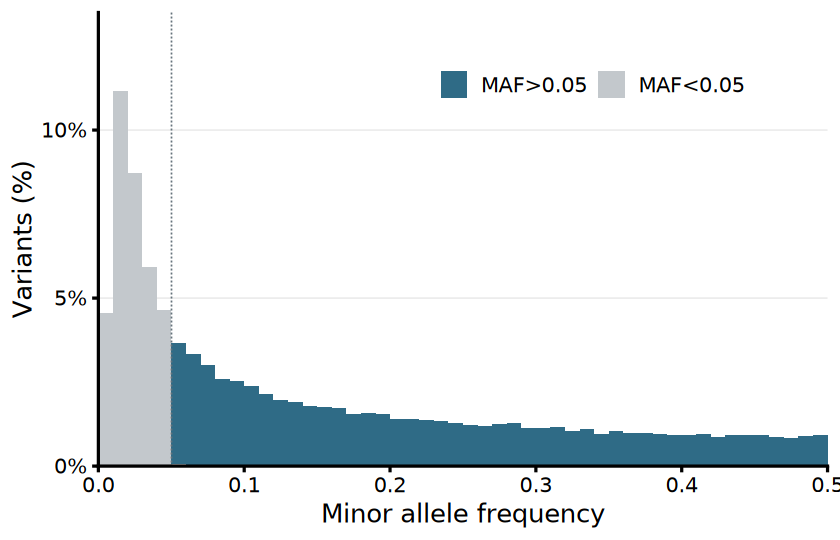

In [2]:
pd <- rbind(
  data.frame(bin_mid = (h$bin_left + h$bin_right) / 2, percent = h$pct_maf_gt_0.05, pool = "MAF>0.05"),
  data.frame(bin_mid = (h$bin_left + h$bin_right) / 2, percent = h$pct_maf_le_0.05, pool = "MAF<0.05"))
pd$pool <- factor(pd$pool, levels = c("MAF>0.05", "MAF<0.05"))

p <- ggplot(pd, aes(x = bin_mid, y = percent, fill = pool)) +
  geom_col(width = 0.01 * 0.94) +
  geom_vline(xintercept = 0.05, colour = "#66737C", linewidth = 0.36, linetype = "22") +
  scale_fill_manual(values = c("MAF>0.05" = "#2F6B86", "MAF<0.05" = "#C3C8CC"), name = NULL) +
  scale_x_continuous(limits = c(0, 0.5), breaks = seq(0, 0.5, 0.1), expand = expansion(mult = 0)) +
  scale_y_continuous(limits = c(0, 13.5), breaks = c(0, 5, 10),
                     labels = function(x) paste0(x, "%"), expand = expansion(mult = 0)) +
  labs(x = "Minor allele frequency", y = "Variants (%)") +
  theme_classic(base_size = 15) +
  theme(legend.position = "inside", legend.position.inside = c(0.9, 0.9),
        legend.justification.inside = c(1, 1), legend.direction = "horizontal",
        panel.grid.major.y = element_line(colour = "#E9E9E9", linewidth = 0.32))

options(repr.plot.width = 7, repr.plot.height = 4.5)
p